<a href="https://colab.research.google.com/github/byuruth/Econ484/blob/main/Kaggle_competition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [70]:
import warnings
warnings.filterwarnings('ignore')

# Import necessary libraries
!git clone https://github.com/byuruth/Econ484.git
%cd Econ484/utilities
from preamble import *
%cd ../data

Cloning into 'Econ484'...
remote: Enumerating objects: 300, done.
remote: Counting objects: 100% (123/123), done.
remote: Compressing objects: 100% (115/115), done.
remote: Total 300 (delta 77), reused 8 (delta 8), pack-reused 177 (from 1)
Receiving objects: 100% (300/300), 14.63 MiB | 22.23 MiB/s, done.
Resolving deltas: 100% (112/112), done.
/content/Econ484/data/Econ484/data/Econ484/utilities
/content/Econ484/data/Econ484/data/Econ484/data


Load and Explore the Datasets

In [71]:
train = pd.read_csv('train.csv')
train['SalePrice'].describe()

,SalePrice
count,1460.0
mean,180921.2
std,79442.5
min,34900.0
25%,129975.0
50%,163000.0
75%,214000.0
max,755000.0


In [72]:
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,...,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,...,2008,WD,Normal,208500
1,2,20,RL,80.0,...,2007,WD,Normal,181500
2,3,60,RL,68.0,...,2008,WD,Normal,223500
3,4,70,RL,60.0,...,2006,WD,Abnorml,140000
4,5,60,RL,84.0,...,2008,WD,Normal,250000


In [73]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [74]:
test = pd.read_csv('test.csv')
test.head()

,Id,MSSubClass,MSZoning,LotFrontage,...,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,...,6,2010,WD,Normal
1,1462,20,RL,81.0,...,6,2010,WD,Normal
2,1463,60,RL,74.0,...,3,2010,WD,Normal
3,1464,60,RL,78.0,...,6,2010,WD,Normal
4,1465,120,RL,43.0,...,1,2010,WD,Normal


Outcome to predict: Sale Price of home





Clean the data, quantify categorical variables

In [75]:
import pandas as pd
import numpy as np

#low to high quality ranking
quality_map = {
    'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5
}

quality_cols = [
    'ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond',
    'HeatingQC', 'KitchenQual', 'FireplaceQu',
    'GarageQual', 'GarageCond', 'PoolQC'
]

#additional variables with rankings
ordinal_maps = {
    'LotShape': {'IR3': 1, 'IR2': 2, 'IR1': 3, 'Reg': 4},
    'Utilities': {'ELO': 1, 'NoSeWa': 2, 'NoSewr': 3, 'AllPub': 4},
    'LandSlope': {'Sev': 1, 'Mod': 2, 'Gtl': 3},
    'BsmtExposure': {'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4},
    'BsmtFinType1': {
        'Unf': 1, 'LwQ': 2, 'Rec': 3,
        'BLQ': 4, 'ALQ': 5, 'GLQ': 6
    },
    'BsmtFinType2': {
        'Unf': 1, 'LwQ': 2, 'Rec': 3,
        'BLQ': 4, 'ALQ': 5, 'GLQ': 6
    },
    'GarageFinish': {'Unf': 1, 'RFn': 2, 'Fin': 3},
    'Functional': {
        'Sal': 1, 'Sev': 2, 'Maj2': 3, 'Maj1': 4,
        'Mod': 5, 'Min2': 6, 'Min1': 7, 'Typ': 8
    },
    'PavedDrive': {'N': 1, 'P': 2, 'Y': 3},
    'Fence': {'MnWw': 1, 'GdWo': 2, 'MnPrv': 3, 'GdPrv': 4},
    'CentralAir': {'N': 0, 'Y': 1}
}

for col in quality_cols:
    ordinal_maps[col] = quality_map

#impute missing values with 0
none_cols = [
    'Alley', 'BsmtQual', 'BsmtCond', 'BsmtExposure',
    'BsmtFinType1', 'BsmtFinType2', 'FireplaceQu',
    'GarageType', 'GarageFinish', 'GarageQual',
    'GarageCond', 'PoolQC', 'Fence', 'MiscFeature',
    'MasVnrType'
]

for df in [train, test]:
    for col in none_cols:
        df[col] = df[col].fillna('None')

    for col, mapping in ordinal_maps.items():
        df[col] = df[col].replace({'None': 0}).map(
            {**mapping, 'None': 0}
        )

#treat as category
for df in [train, test]:
    df['MSSubClass'] = df['MSSubClass'].astype(str)

#impute again
numeric_cols = train.select_dtypes(
    include=np.number
).columns.drop('SalePrice')

for col in numeric_cols:
    median = train[col].median()
    train[col] = train[col].fillna(median)
    test[col] = test[col].fillna(median)

categorical_cols = train.select_dtypes(
    include=['object', 'category', 'string']
).columns

for col in categorical_cols:
    train[col] = train[col].fillna('Missing')
    test[col] = test[col].fillna('Missing')

#encode categorical variables
train = pd.get_dummies(
    train, columns=categorical_cols, dtype=int
)

test = pd.get_dummies(
    test, columns=categorical_cols, dtype=int
)

#realign
test = test.reindex(
    columns=train.drop(columns=['SalePrice']).columns,
    fill_value=0
)

test.head()


,Id,LotFrontage,LotArea,LotShape,...,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,1461,80.0,11622,4,...,0,0,1,0
1,1462,81.0,14267,3,...,0,0,1,0
2,1463,74.0,13830,3,...,0,0,1,0
3,1464,78.0,9978,3,...,0,0,1,0
4,1465,43.0,5005,3,...,0,0,1,0


## Penalized Regression Prediction

In [76]:
import pandas as pd
import numpy as np
from sklearn import linear_model
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

In [77]:
#ols benchmark

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
import numpy as np

#prepare data
X = train.drop(columns=['SalePrice', 'Id'])
y = train['SalePrice']
scaler = StandardScaler()
scaler.fit(X)
X_scaled = scaler.transform(X)

#cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Create OLS model
ols = LinearRegression().fit(X_scaled,y)
yhat = ols.predict(X_scaled)


In [78]:
#Lasso

lassocv=linear_model.LassoCV(random_state=42).fit(X_scaled,y)
# print out the chosen value for alpha
print("Chosen alpha: {:.3f}".format(lassocv.alpha_))
# print the original number of regressors and the number selected by lasso
print("Number of regressors in the menu: ",len(X.columns))
print("Number of regressors selected by lasso: ",sum(lassocv.coef_!=0))
results = pd.DataFrame({'feature': X.columns[lassocv.coef_!=0],'coefficient': lassocv.coef_[lassocv.coef_!=0]})
results

Chosen alpha: 1177.058
Number of regressors in the menu:  239
Number of regressors selected by lasso:  63


,feature,coefficient
0,LotFrontage,653.85
1,LotArea,3227.83
2,OverallQual,12956.11
3,OverallCond,3388.44
4,YearBuilt,2205.87
...,...,...
58,GarageType_BuiltIn,202.49
59,SaleType_Con,374.71
60,SaleType_New,5042.95
61,SaleCondition_Abnorml,-1031.58


In [79]:
#Ridge
ridgecv=linear_model.RidgeCV(cv=5,alphas=(.1,1,10,50,100,1000)).fit(X_scaled,y)
print("Chosen alpha: {:.3f}".format(ridgecv.alpha_))
print("Accuracy on training set: {:.3f}".format(ridgecv.score(X_scaled,y)))
# look at the coefficients
results = pd.DataFrame({'feature': X.columns[ridgecv.coef_!=0],'coefficient': ridgecv.coef_[ridgecv.coef_!=0]})
results

Chosen alpha: 1000.000
Accuracy on training set: 0.888


,feature,coefficient
0,LotFrontage,1503.78
1,LotArea,2575.16
2,LotShape,-723.21
3,Utilities,721.16
4,LandSlope,-630.95
...,...,...
234,SaleCondition_AdjLand,-4.21
235,SaleCondition_Alloca,238.85
236,SaleCondition_Family,-851.38
237,SaleCondition_Normal,-187.96


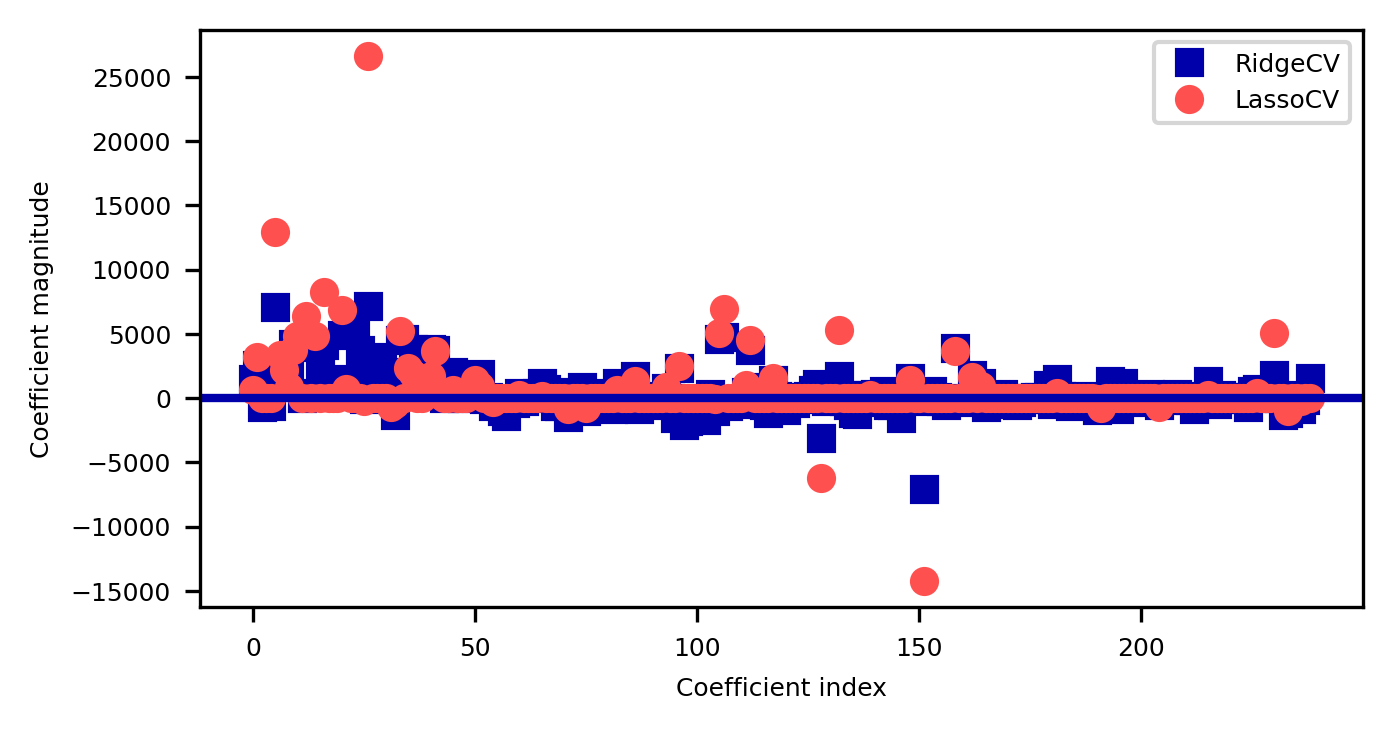

In [80]:
plt.plot(ridgecv.coef_, 's', label="RidgeCV")
plt.plot(lassocv.coef_, 'o', label="LassoCV")
plt.xlabel("Coefficient index")
plt.ylabel("Coefficient magnitude")
xlims = plt.xlim()
plt.hlines(0, xlims[0], xlims[1])
plt.xlim(xlims)
plt.legend()

In [81]:
print("OLS RMSE: $", round(np.sqrt(ols_mse), 2))
print("Lasso RMSE: $", round(np.sqrt(lasso_mse), 2))
print("Ridge RMSE: $", round(np.sqrt(ridge_mse), 2))

OLS RMSE: $ 22493.62
Lasso RMSE: $ 25178.15
Ridge RMSE: $ 26524.93


it looks like OLS has the best in sample predictions (not really surprised by this). We can't see which one makes more accurate predictions out of sample, the the visual shoes us that lasso shrunk some of the coefficients all the way to zero.

## Random Forest Prediction

In [87]:
from sklearn.ensemble import RandomForestRegressor

X = train.drop(columns=['SalePrice', 'Id'])
y = train['SalePrice']

#random forest
forest = RandomForestRegressor(n_estimators=5, random_state=2, bootstrap=True)
forest.fit(X, y)

RandomForestRegressor(n_estimators=5, random_state=2)

In [88]:
#make predictions
X_test = test[X.columns]

#standardize data
X_test_scaled = scaler.transform(X_test)

ols_predictions = ols.predict(X_test_scaled)
lasso_predictions = lassocv.predict(X_test_scaled)
ridge_predictions = ridgecv.predict(X_test_scaled)

#random forest prediction
forest_predictions = forest.predict(X_test)

#compare predictions
predictions = pd.DataFrame({
    'OLS': ols_predictions,
    'Lasso': lasso_predictions,
    'Ridge': ridge_predictions,
    'Random Forest': forest_predictions
})

predictions.head(10)




,OLS,Lasso,Ridge,Random Forest
0,117726.90,114233.44,112839.96,121680.0
1,158663.72,169551.44,167116.72,152390.0
2,177767.70,175434.51,182543.48,181100.0
3,182606.75,180202.32,195720.89,179600.0
4,219795.26,216519.29,212244.80,183400.0
5,166408.20,166397.59,171058.10,184040.0
6,173883.60,171396.07,176229.54,178900.0
7,155060.63,155158.11,167781.54,175537.0
8,203840.31,202283.59,186489.85,182800.0
9,108745.79,111734.98,120413.78,125580.0
